q.1 Equilibrium conversion checker -In a liquid-phase reactor the reaction A+B gives c reaches equilibrium initial concentrations are [A]0  = 1.0, and [B]o =1.0 and [c]o =  0 mol/L of  C is formed, Kc = x/(1-x)^2,which rearranges to the quadratic equation Kc.x^2 -(2Kc +1).x + Kc =0.Write a Python program that :(a)reads Kc using input(),prints the data type of the raw input and of the converted value,and shows a clear message (no crash) if the text is not a number or if Kc<= 0; (b) finds a,b,c the descriminant and both roots; (c) selects the physically meaningful root (0<= x <= 1); (d) prints equilibrium [A],[B],[C] (3 decimals) and the conversion of the limiting reactant = x/[A]0 * 100 (%); (e)classifies the conversion using if /elif /else :>=70 % "High",>= 40 % "Moderate", otherwise "Low". Test with Kc =4 ,Kc=0.5 , Kc=abc and Kc = -2.  

# Equilibrium Conversion Checker

For the simplified reaction A + B ⇌ C, the initial concentrations are [A]₀ = [B]₀ = 1.0 mol/L and [C]₀ = 0 mol/L. The equilibrium extent `x` satisfies:

```text
Kc = x / (1 - x)²
Kc*x² - (2*Kc + 1)*x + Kc = 0
```

Run the code cell and enter a positive numeric value for `Kc`.

In [10]:
import math

raw_kc = input("Enter Kc: ")
print("Raw input type:", type(raw_kc))

try:
    kc = float(raw_kc)
except ValueError:
    print("Invalid input: Kc must be a number.")
else:
    print("Converted value:", kc)
    print("Converted value type:", type(kc))

    if not math.isfinite(kc):
        print("Invalid input: Kc must be a finite number.")
    elif kc <= 0:
        print("Invalid input: Kc must be greater than 0.")
    else:
        a = kc
        b = -(2 * kc + 1)
        c = kc
        discriminant = b**2 - 4 * a * c

        print(f"\na = {a}, b = {b}, c = {c}")
        print("Discriminant:", discriminant)

        root1 = (-b + math.sqrt(discriminant)) / (2 * a)
        root2 = (-b - math.sqrt(discriminant)) / (2 * a)
        print("Root 1:", root1)
        print("Root 2:", root2)

        if 0 <= root1 <= 1:
            x = root1
        elif 0 <= root2 <= 1:
            x = root2
        else:
            print("No physically meaningful root in the range 0 <= x <= 1.")
            x = None

        if x is not None:
            concentration_a0 = 1.0
            concentration_a = concentration_a0 - x
            concentration_b = 1.0 - x
            concentration_c = x
            conversion = x / concentration_a0 * 100

            print(f"\nPhysical root x: {x:.6f}")
            print(f"Equilibrium [A]: {concentration_a:.3f} mol/L")
            print(f"Equilibrium [B]: {concentration_b:.3f} mol/L")
            print(f"Equilibrium [C]: {concentration_c:.3f} mol/L")
            print(f"Limiting-reactant conversion: {conversion:.2f}%")

            if conversion >= 70:
                classification = "High"
            elif conversion >= 40:
                classification = "Moderate"
            else:
                classification = "Low"

            print("Conversion classification:", classification)

Raw input type: <class 'str'>
Converted value: 0.5
Converted value type: <class 'float'>

a = 0.5, b = -2.0, c = 0.5
Discriminant: 3.0
Root 1: 3.732050807568877
Root 2: 0.2679491924311228

Physical root x: 0.267949
Equilibrium [A]: 0.732 mol/L
Equilibrium [B]: 0.732 mol/L
Equilibrium [C]: 0.268 mol/L
Limiting-reactant conversion: 26.79%
Conversion classification: Low


## Test cases

| Input | Expected result |
|---|---|
| `4` | Physical root ≈ 0.609612; [A] = [B] = 0.390 mol/L; [C] = 0.610 mol/L; conversion ≈ 60.96% (Moderate) |
| `0.5` | Physical root ≈ 0.267949; [A] = [B] = 0.732 mol/L; [C] = 0.268 mol/L; conversion ≈ 26.79% (Low) |
| `abc` | Clear message that Kc must be a number; no traceback |
| `-2` | Clear message that Kc must be greater than 0; no traceback |

Q.2 Batch reactor simulation and batch  tracking 
Part A. A batch reactor decomposes reactant  A (A-> products) by a first - order raction , dC /dt = -kC. Use the Euler  methos : C_new = C_old - k.Cold.dt. Take C0 = 2.0 mol/L, k=0.08 min^-1,dt = 1 min.
(i) Using  a for loop , simulate 10 minutes and print a table of Time (min), Concentration (mol/L) and Conversion(%).
(ii) Using math.exp (), calculate the exact value C0e^(-kt) at 10 min and print the absolute error of the Euler result.
(iii)Using a while loop,repeat the simulation until conversion reaches 60 % or time reaches 100 min. Print the time needed and the final concentration.

Part B. A Batch labels such as PLANT20261030  are stored as text. Write a program  that reaches a label, loops through each character,and prints the number of digits and the sum of the digits. Show a message for an empty label and for a label with no digits. Test with PLANT20261030,an empty label and ABCDEF.

In [2]:
import math

initial_concentration = 2.0  # mol/L
k = 0.08  # min^-1
dt = 1.0  # min

# Part A(i): Euler simulation for 10 minutes.
time = 0
concentration = initial_concentration

print(f"{'Time (min)':>10} {'Concentration (mol/L)':>24} {'Conversion (%)':>18}")
for time in range(11):
    conversion = (initial_concentration - concentration) / initial_concentration * 100
    print(f"{time:10d} {concentration:24.4f} {conversion:18.2f}")
    if time < 10:
        concentration = concentration - k * concentration * dt

# Part A(ii): compare the Euler result at 10 minutes with the exact result.
euler_concentration_10 = concentration
exact_concentration_10 = initial_concentration * math.exp(-k * 10)
absolute_error = abs(euler_concentration_10 - exact_concentration_10)

print(f"\nEuler concentration at 10 min: {euler_concentration_10:.6f} mol/L")
print(f"Exact concentration at 10 min: {exact_concentration_10:.6f} mol/L")
print(f"Absolute error: {absolute_error:.6f} mol/L")

# Part A(iii): continue with Euler steps until conversion reaches 60% or time reaches 100 min.
time = 0
concentration = initial_concentration
conversion = 0.0

while conversion < 60 and time < 100:
    concentration = concentration - k * concentration * dt
    time += dt
    conversion = (initial_concentration - concentration) / initial_concentration * 100

print(f"\nTime to reach 60% conversion (Euler): {time:g} min")
print(f"Concentration at that time: {concentration:.6f} mol/L")
print(f"Conversion at that time: {conversion:.2f}%")

Time (min)    Concentration (mol/L)     Conversion (%)
         0                   2.0000               0.00
         1                   1.8400               8.00
         2                   1.6928              15.36
         3                   1.5574              22.13
         4                   1.4328              28.36
         5                   1.3182              34.09
         6                   1.2127              39.36
         7                   1.1157              44.22
         8                   1.0264              48.68
         9                   0.9443              52.78
        10                   0.8688              56.56

Euler concentration at 10 min: 0.868777 mol/L
Exact concentration at 10 min: 0.898658 mol/L
Absolute error: 0.029881 mol/L

Time to reach 60% conversion (Euler): 11 min
Concentration at that time: 0.799275 mol/L
Conversion at that time: 60.04%


In [3]:
def analyze_batch_label(label):
    if label == "":
        print("The batch label is empty.")
        return

    digit_count = 0
    digit_sum = 0

    for character in label:
        if character.isdecimal():
            digit_count += 1
            digit_sum += int(character)

    if digit_count == 0:
        print("The batch label contains no digits.")
    else:
        print(f"Number of digits: {digit_count}")
        print(f"Sum of digits: {digit_sum}")


batch_label = input("Enter a batch label: ")
analyze_batch_label(batch_label)

Number of digits: 2
Sum of digits: 7


In [4]:
# Part B test cases
for test_label in ("PLANT20261030", "", "ABCDEF"):
    print(f"\nLabel: {test_label!r}")
    analyze_batch_label(test_label)


Label: 'PLANT20261030'
Number of digits: 8
Sum of digits: 14

Label: ''
The batch label is empty.

Label: 'ABCDEF'
The batch label contains no digits.


Q.3. Additive screening and smapling schedule
Part A. A laboratory has n candidates additives and wants to test r of them together in one formulation (order does not matter).Write  a recursive function factorial (n)(remember the base case for 0!) and a fuvtion combination (n,r) =n!/(r!(n-r)!) that uses ot. Reject invalid input (negative values, r>n ). Print the number of possible formulations for n=6 , r=3 , and show the message for n=5, r=7.

Part B. During a reaction, samples are taken at times = Fibonacci number * 2 min. Write  an iterative function fib_iter(n) that returns a list of the first  n fibonacci numbers, and a recursive function fib_rec(k)  that returns the k-th Fibonacci number (F0 = 0, F1 =1). For n =10 ,check  that both functions agree and print a table: Sample No. | Fibonacci tag | Sampling time(min).

In [5]:
def factorial(n):
    if not isinstance(n, int) or isinstance(n, bool):
        raise ValueError("n must be an integer.")
    if n < 0:
        raise ValueError("n must be non-negative.")
    if n == 0:
        return 1
    return n * factorial(n - 1)


def combination(n, r):
    if not isinstance(n, int) or isinstance(n, bool) or not isinstance(r, int) or isinstance(r, bool):
        raise ValueError("n and r must be integers.")
    if n < 0 or r < 0:
        raise ValueError("n and r must be non-negative.")
    if r > n:
        raise ValueError("r cannot be greater than n.")
    return factorial(n) // (factorial(r) * factorial(n - r))


try:
    print("Possible formulations for n=6, r=3:", combination(6, 3))
except ValueError as error:
    print("Invalid combination:", error)

try:
    print("Possible formulations for n=5, r=7:", combination(5, 7))
except ValueError as error:
    print("Invalid combination for n=5, r=7:", error)


def fib_iter(n):
    if not isinstance(n, int) or isinstance(n, bool):
        raise ValueError("n must be an integer.")
    if n < 0:
        raise ValueError("n must be non-negative.")

    sequence = []
    previous, current = 0, 1
    for _ in range(n):
        sequence.append(previous)
        previous, current = current, previous + current
    return sequence


def fib_rec(k):
    if not isinstance(k, int) or isinstance(k, bool):
        raise ValueError("k must be an integer.")
    if k < 0:
        raise ValueError("k must be non-negative.")
    if k == 0:
        return 0
    if k == 1:
        return 1
    return fib_rec(k - 1) + fib_rec(k - 2)


n = 10
fibonacci_tags = fib_iter(n)
recursive_tags = [fib_rec(index) for index in range(n)]

if fibonacci_tags == recursive_tags:
    print("\nIterative and recursive Fibonacci values agree.")
else:
    print("\nError: Fibonacci implementations do not agree.")

print(f"{'Sample No.':>10} {'Fibonacci tag':>14} {'Sampling time (min)':>21}")
for sample_number, tag in enumerate(fibonacci_tags, start=1):
    sampling_time = tag * 2
    print(f"{sample_number:10d} {tag:14d} {sampling_time:21d}")

Possible formulations for n=6, r=3: 20
Invalid combination for n=5, r=7: r cannot be greater than n.

Iterative and recursive Fibonacci values agree.
Sample No.  Fibonacci tag   Sampling time (min)
         1              0                     0
         2              1                     2
         3              1                     2
         4              2                     4
         5              3                     6
         6              5                    10
         7              8                    16
         8             13                    26
         9             21                    42
        10             34                    68


Q.4 Kinetics and gas data : pandas  and matplotlib
Hydrolysis  of an ester was studied at two temperatures. The concentration(mol/L ) was recorded:
Time_min = [0,10,20,30,40,50];
Run1_mol_L(low T) =[1.00,0.74,0.55,0.41,0.30,0.22];
Run2_mol_L(high T) = [1.00,0.61,0.37,0.22,0.14,0.08]
(a) Create  a Dataframe from this table.Save it as kinetics.csv (without the index column) and as kinetics.json. Read the CSV back and print its shape and data types.
(b) Print the mean and standard deviation of Run1 and Run2 ,and state which run shows more variation.
(c) Plot both runs on one graph (Time on x-axis ) with title, axis labels with units, legend and grid.
(d) Nitrogen gas is compressed slowly in a piston-cylinder at constant temperature:
Volume_L =[1,2,3,4,5];
Pressure_bar = [4.00,2.03,1.31,1.02,0.81]
Plot pressure vs. volume as a scatter plot. Calculate k as the mean of P x V and draw the reference curve P = k/V on the same graph. And title, labels with units and legend.

CSV shape: (6, 3)
CSV data types:
 Time_min               int64
Run1_mol_L_low_T     float64
Run2_mol_L_high_T    float64
dtype: object

Run 1 mean: 0.5367 mol/L
Run 1 standard deviation: 0.2928 mol/L
Run 2 mean: 0.4033 mol/L
Run 2 standard deviation: 0.3485 mol/L
Run 2 shows more variation based on standard deviation.


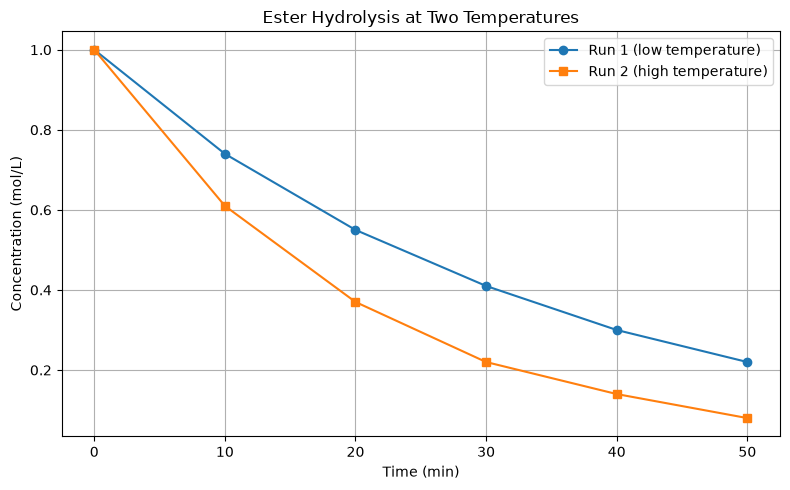

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

kinetics_data = {
    "Time_min": [0, 10, 20, 30, 40, 50],
    "Run1_mol_L_low_T": [1.00, 0.74, 0.55, 0.41, 0.30, 0.22],
    "Run2_mol_L_high_T": [1.00, 0.61, 0.37, 0.22, 0.14, 0.08],
}
kinetics_df = pd.DataFrame(kinetics_data)

kinetics_df.to_csv("kinetics.csv", index=False)
kinetics_df.to_json("kinetics.json", orient="records", indent=2)

kinetics_from_csv = pd.read_csv("kinetics.csv")
print("CSV shape:", kinetics_from_csv.shape)
print("CSV data types:\n", kinetics_from_csv.dtypes)

run1_mean = kinetics_from_csv["Run1_mol_L_low_T"].mean()
run1_std = kinetics_from_csv["Run1_mol_L_low_T"].std()
run2_mean = kinetics_from_csv["Run2_mol_L_high_T"].mean()
run2_std = kinetics_from_csv["Run2_mol_L_high_T"].std()

print(f"\nRun 1 mean: {run1_mean:.4f} mol/L")
print(f"Run 1 standard deviation: {run1_std:.4f} mol/L")
print(f"Run 2 mean: {run2_mean:.4f} mol/L")
print(f"Run 2 standard deviation: {run2_std:.4f} mol/L")

if run1_std > run2_std:
    print("Run 1 shows more variation based on standard deviation.")
elif run2_std > run1_std:
    print("Run 2 shows more variation based on standard deviation.")
else:
    print("Both runs have the same standard deviation.")

plt.figure(figsize=(8, 5))
plt.plot(kinetics_from_csv["Time_min"], kinetics_from_csv["Run1_mol_L_low_T"], marker="o", label="Run 1 (low temperature)")
plt.plot(kinetics_from_csv["Time_min"], kinetics_from_csv["Run2_mol_L_high_T"], marker="s", label="Run 2 (high temperature)")
plt.title("Ester Hydrolysis at Two Temperatures")
plt.xlabel("Time (min)")
plt.ylabel("Concentration (mol/L)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

Mean value of P x V (k): 4.024 bar·L


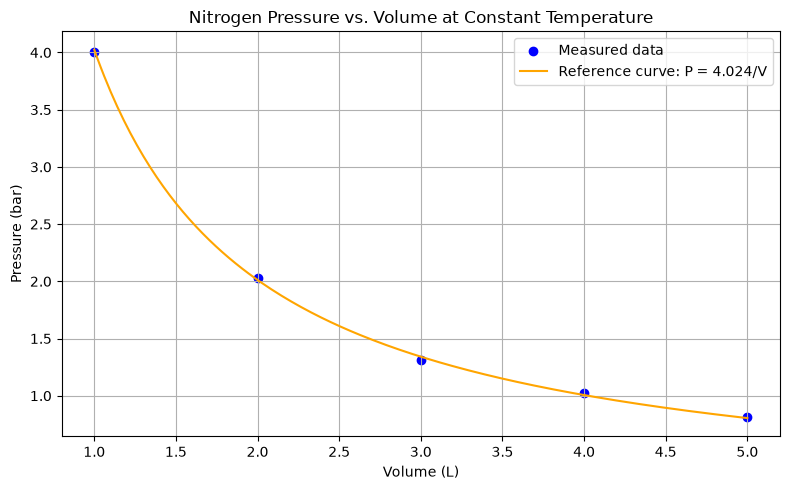

In [12]:
import numpy as np

gas_data = pd.DataFrame({
    "Volume_L": [1, 2, 3, 4, 5],
    "Pressure_bar": [4.00, 2.03, 1.31, 1.02, 0.81],
})

k = (gas_data["Pressure_bar"] * gas_data["Volume_L"]).mean()
print(f"Mean value of P x V (k): {k:.3f} bar·L")

reference_volume = np.linspace(gas_data["Volume_L"].min(), gas_data["Volume_L"].max(), 200)
reference_pressure = k / reference_volume

plt.figure(figsize=(8, 5))
plt.scatter(gas_data["Volume_L"], gas_data["Pressure_bar"], color="blue", label="Measured data")
plt.plot(reference_volume, reference_pressure, color="orange", label=f"Reference curve: P = {k:.3f}/V")
plt.title("Nitrogen Pressure vs. Volume at Constant Temperature")
plt.xlabel("Volume (L)")
plt.ylabel("Pressure (bar)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()